In [ ]:
zximport pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/House Price Prediction Dataset.csv")
df

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056
...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119


In [ ]:
#1. Gather the Data
| Area (sq.ft) |  Price |
| -----------: | -----: |
|         1000 | 150000 |
|         1200 | 180000 |
|         1500 | 225000 |
|         1800 | 270000 |
|         2000 | 300000 |
|         2200 | 330000 |
|         2500 | 375000 |
|         2800 | 420000 |
|         3000 | 450000 |
|         3200 | 480000 |


   Area   Price
0  1000  150000
1  1200  180000
2  1500  225000
3  1800  270000
4  2000  300000
5  2200  330000
6  2500  375000
7  2800  420000
8  3000  450000
9  3200  480000

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Area    10 non-null     int64
 1   Price   10 non-null     int64
dtypes: int64(2)
memory usage: 292.0 bytes
None

Statistical Summary:
              Area          Price
count    10.000000      10.000000
mean   2120.000000  318000.000000
std     756.894239  113534.135836
min    1000.000000  150000.000000
25%    1575.000000  236250.000000
50%    2100.000000  315000.000000
75%    2725.000000  408750.000000
max    3200.000000  480000.000000


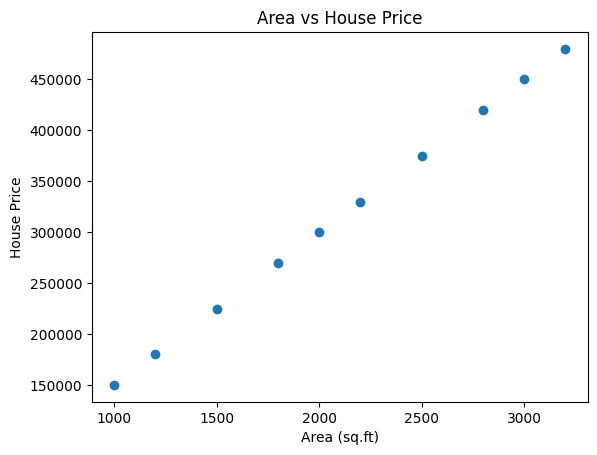

In [ ]:
#2. Import Libraries and Analyze Data
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create dataset
data = {
    "Area": [1000, 1200, 1500, 1800, 2000,
             2200, 2500, 2800, 3000, 3200],
    "Price": [150000, 180000, 225000, 270000, 300000,
              330000, 375000, 420000, 450000, 480000]
}

df = pd.DataFrame(data)

# Display dataset
print(df)

# Analyze data
print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

# Visualize data
plt.scatter(df["Area"], df["Price"])
plt.xlabel("Area (sq.ft)")
plt.ylabel("House Price")
plt.title("Area vs House Price")
plt.show()

In [ ]:
#3. Create the Linear Regression Model
# Independent variable
X = df[["Area"]]

# Dependent variable
y = df["Price"]

# Split data into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display coefficient and intercept
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 150.00000000000003
Intercept: -5.820766091346741e-11


In [ ]:
#4. Prediction and Performance
# Predict house prices using test data
y_pred = model.predict(X_test)

print("Actual Prices:")
print(y_test.values)

print("\nPredicted Prices:")
print(y_pred)

# Performance evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Actual Prices:
[450000 180000]

Predicted Prices:
[450000. 180000.]

Mean Absolute Error: 1.4551915228366852e-11
Mean Squared Error: 4.235164736271502e-22
R2 Score: 1.0


In [ ]:
#2025
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Load MPG dataset
df = pd.read_csv("/content/auto-mpg.csv")

# Replace '?' with NaN in 'horsepower' column and convert to numeric
df['horsepower'] = df['horsepower'].replace('?', np.nan).astype(float)

# Remove missing values (now includes rows where 'horsepower' was '?')
df = df.dropna(subset=["mpg", "horsepower"])

# Independent and dependent variables
X = df[["horsepower"]]
y = df["mpg"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R2 Score :", r2)

MAE  : 3.782512710126959
MSE  : 22.153237123863413
RMSE : 4.706722545876633
R2 Score : 0.5659681822256185


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

# Load dataset
df = pd.read_csv("/content/Iris.csv")

# Features and target
X = df.drop("Species", axis=1)
y = df["Species"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Decision Tree model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred, average="weighted"))
print("F1-Score :", f1_score(y_test, y_pred, average="weighted"))

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-Score : 1.0


CIE-4

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

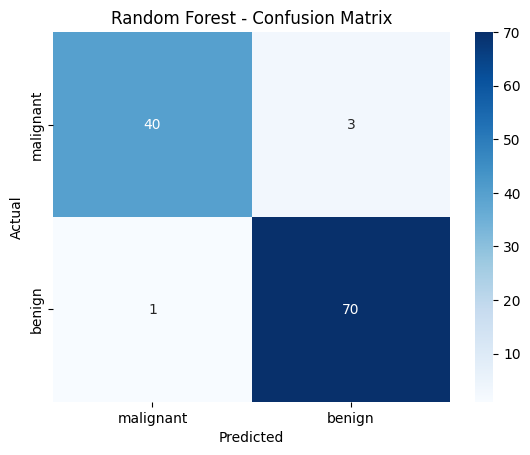

In [ ]:
#Build Random Forest-based model in Python for Breast Cancer Wisconsin (Diagnostic) dataset.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Display data
print(X.head())
print(y[:5])

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build Random Forest model
model = RandomForestClassifier(n_estimators=100,random_state=42)

# Train the model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Visualize confusion matrix
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=data.target_names,yticklabels=data.target_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

Axes(0.125,0.11;0.62x0.77)


<Axes: >

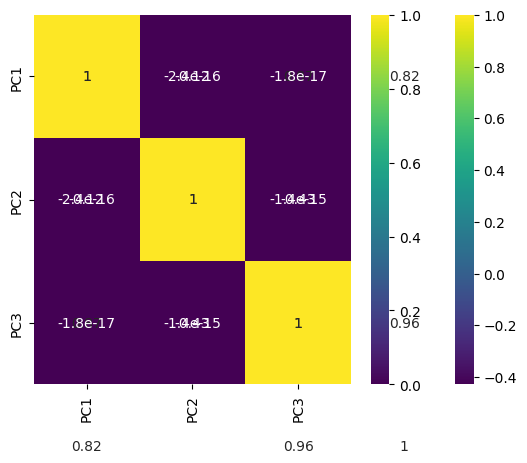

In [ ]:
from sklearn import datasets
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns

iris=datasets.load_iris()
df=pd.DataFrame(iris["data"],columns=iris["feature_names"])
df.head()

scaler=StandardScaler()
scaled_data=pd.DataFrame(scaler.fit_transform(df),columns=df.columns)
scaled_data.head()

print(sns.heatmap(scaled_data.corr() ,cmap='viridis',annot=True))

pca=PCA(n_components=3)
pca.fit(scaled_data)
data_pca=pca.transform(scaled_data)h
data_pca=pd.DataFrame(data_pca,columns=['PC1','PC2','PC3'])
data_pca.head()

sns.heatmap(data_pca.corr(),cmap='viridis',annot=True)


   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


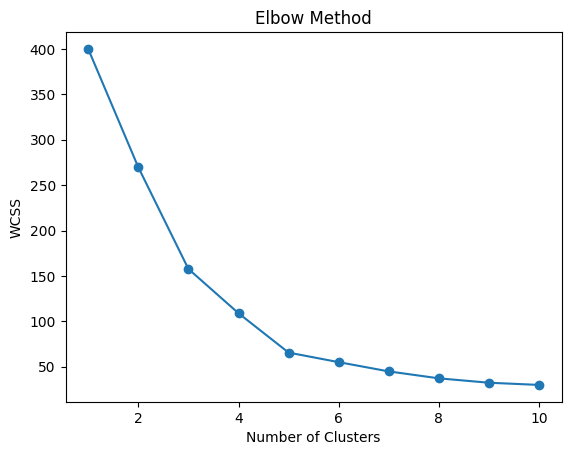

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  
Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64


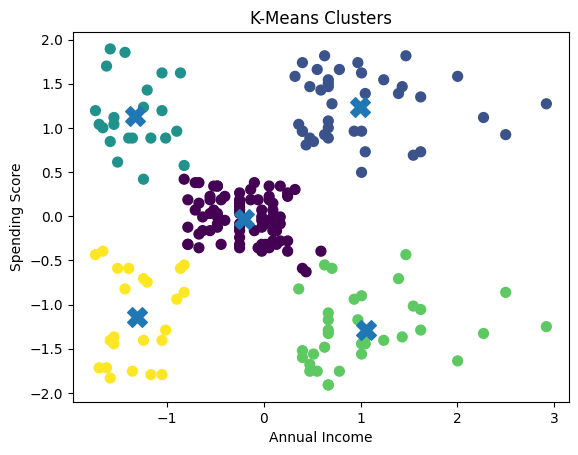

In [ ]:
#data preprocessing, elbow method, K-Means training, and cluster visualization
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv("/content/Mall_Customers.csv")

# Display data
print(df.head())
print(df.info())

# Data preprocessing
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

# Train K-Means model
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
y_pred = kmeans.fit_predict(X_scaled)

# Add cluster column
df['Cluster'] = y_pred

print(df.head())
print(df['Cluster'].value_counts())

# Visualize clusters
plt.scatter(X_scaled[:, 0],X_scaled[:, 1],c=y_pred,s=50)

# Plot centroids
plt.scatter( kmeans.cluster_centers_[:, 0],kmeans.cluster_centers_[:, 1],s=200,marker='X')

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('K-Means Clusters')
plt.show()

In [ ]:
#implement averagging ensemble technique
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create models
model1 = LogisticRegression(max_iter=1000)
model2 = DecisionTreeClassifier(random_state=42)
model3 = KNeighborsClassifier()

# Train models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

# Get prediction probabilities
p1 = model1.predict_proba(X_test)
p2 = model2.predict_proba(X_test)
p3 = model3.predict_proba(X_test)

# Averaging
average_probability = (p1 + p2 + p3) / 3

# Final prediction
y_pred = np.argmax(average_probability, axis=1)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Averaging Ensemble Accuracy:", accuracy)

Averaging Ensemble Accuracy: 0.9736842105263158


In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.linear_model import LinearRegression

df = pd.read_csv("/content/train.csv")

target = df["Survived"]
train = df.drop("Survived", axis=1)

# Drop non-numeric columns that cause ValueError
train = train.drop(columns=['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], errors='ignore')

X_train, X_test, y_train, y_test = train_test_split(
    train, target, test_size=0.20, random_state=42
)

model_1 = LinearRegression()
model_2 = xgb.XGBRegressor()
model_3 = RandomForestRegressor()

model_1.fit(X_train, y_train)
model_2.fit(X_train, y_train)
model_3.fit(X_train, y_train)

pred_1 = model_1.predict(X_test)
pred_2 = model_2.predict(X_test)
pred_3 = model_3.predict(X_test)

pred_final = (pred_1 + pred_2 + pred_3) / 3.0

print(mean_squared_error(y_test, pred_final))

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

CIE--5

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.3438 - loss: 1.0627 - val_accuracy: 0.5833 - val_loss: 0.9990
Epoch 2/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4479 - loss: 0.9899 - val_accuracy: 0.6250 - val_loss: 0.9496
Epoch 3/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5104 - loss: 0.9283 - val_accuracy: 0.7083 - val_loss: 0.9050
Epoch 4/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5833 - loss: 0.8772 - val_accuracy: 0.7083 - val_loss: 0.8687
Epoch 5/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6250 - loss: 0.8305 - val_accuracy: 0.7083 - val_loss: 0.8370
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 391ms/step - accuracy: 0.6667 - loss: 0.8073
Test Accuracy: 0.6666666865348816


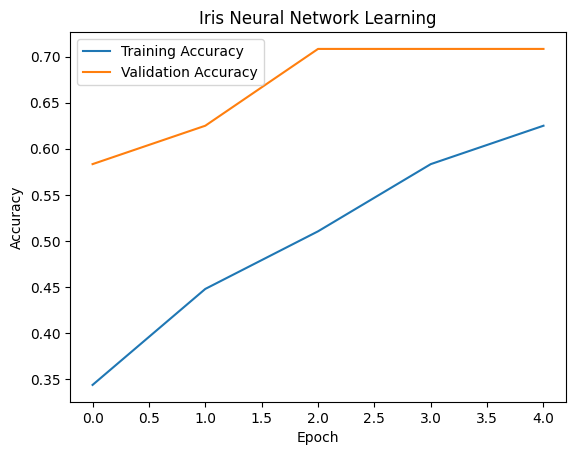

In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt
import datetime
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import TensorBoard

iris = load_iris()
X = iris.data
y = iris.target

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Sequential([
    Input(shape=(4,)),
    Dense(10, activation="relu"),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard = TensorBoard(log_dir=log_dir)

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=8,
    validation_split=0.2,
    callbacks=[tensorboard],
    verbose=1
)

loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

tf.keras.utils.plot_model(
    model,
    to_file="iris_architecture.png",
    show_shapes=True,
    show_layer_names=True
)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Iris Neural Network Learning")
plt.legend()
plt.savefig("iris_accuracy.png")
plt.show()


In [ ]:

import re
from collections import Counter

text = input("Enter a paragraph: ")
n = int(input("Enter number of sentences in summary: "))

sentences = re.split(r'(?<=[.!?])\s+', text.strip())

words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

stop_words = {
    "the", "is", "a", "an", "and", "of", "to",
    "in", "for", "on", "are", "it", "with", "that"
}

words = [word for word in words if word not in stop_words]
frequency = Counter(words)

scores = []

for sentence in sentences:
    sentence_words = re.findall(r'\b[a-zA-Z]+\b', sentence.lower())
    score = sum(frequency[word] for word in sentence_words)
    scores.append(score)

top_indices = sorted(
    range(len(sentences)),
    key=lambda i: scores[i],
    reverse=True
)[:n]

summary = [sentences[i] for i in sorted(top_indices)]

print("\nSummary:")
print(" ".join(summary))





In [1]:
import spacy
from nltk import ngrams
nlp = spacy.load("en_core_web_sm")
doc = nlp("AI is simulation of human Intelligence by machine. It includes experts system NLP speech recognition and machine vision.")
bigrams = ngrams(doc, 2)
print(list(bigrams))
trigrams = ngrams(doc, 3)
print(list(trigrams))

[(AI, is), (is, simulation), (simulation, of), (of, human), (human, Intelligence), (Intelligence, by), (by, machine), (machine, .), (., It), (It, includes), (includes, experts), (experts, system), (system, NLP), (NLP, speech), (speech, recognition), (recognition, and), (and, machine), (machine, vision), (vision, .)]
[(AI, is, simulation), (is, simulation, of), (simulation, of, human), (of, human, Intelligence), (human, Intelligence, by), (Intelligence, by, machine), (by, machine, .), (machine, ., It), (., It, includes), (It, includes, experts), (includes, experts, system), (experts, system, NLP), (system, NLP, speech), (NLP, speech, recognition), (speech, recognition, and), (recognition, and, machine), (and, machine, vision), (machine, vision, .)]


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.2604 - loss: 1.3144 - val_accuracy: 0.2083 - val_loss: 1.4624
Epoch 2/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2604 - loss: 1.2602 - val_accuracy: 0.2083 - val_loss: 1.3722
Epoch 3/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2500 - loss: 1.2052 - val_accuracy: 0.1667 - val_loss: 1.2971
Epoch 4/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2292 - loss: 1.1604 - val_accuracy: 0.1667 - val_loss: 1.2244
Epoch 5/5
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.2500 - loss: 1.1151 - val_accuracy: 0.2083 - val_loss: 1.1569
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 343ms/step - accuracy: 0.2333 - loss: 1.1487
Test Accuracy: 0.23333333432674408


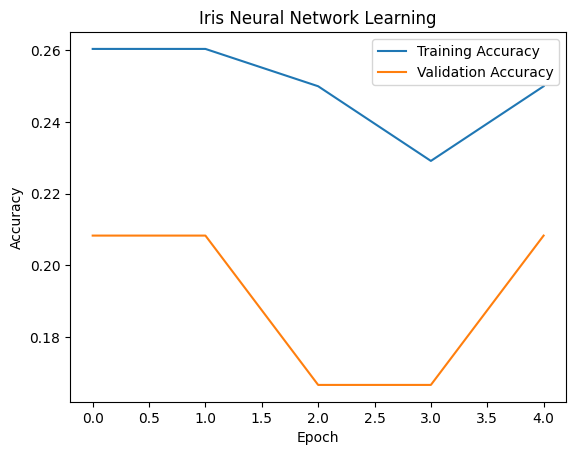

In [2]:

import tensorflow as tf
import matplotlib.pyplot as plt
import datetime
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import TensorBoard

iris = load_iris()
X = iris.data
y = iris.target

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Sequential([
    Input(shape=(4,)),
    Dense(10, activation="relu"),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard = TensorBoard(log_dir=log_dir)

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=8,
    validation_split=0.2,
    callbacks=[tensorboard],
    verbose=1
)

loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

tf.keras.utils.plot_model(
    model,
    to_file="iris_architecture.png",
    show_shapes=True,
    show_layer_names=True
)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Iris Neural Network Learning")
plt.legend()
plt.savefig("iris_accuracy.png")
plt.show()